# Car Price Prediction with Machine Learning
**CodeAlpha Data Science Internship, Task 3**

Goal: predict the selling price of a used vehicle (in lakhs) from features such as age, original price, kilometres driven, fuel type, seller type, transmission and number of previous owners.

## 1. Import libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load and inspect the data

In [4]:
df = pd.read_csv("car data.csv")
print("Shape:", df.shape)
df.head()

Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [5]:
df.info()
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing values: 0
Duplicate rows: 2


,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.00,301.00,301.00,301.00,301.00
mean,2013.63,4.66,7.63,36947.21,0.04
std,2.89,5.08,8.64,38886.88,0.25
min,2003.00,0.10,0.32,500.00,0.00
25%,2012.00,0.90,1.20,15000.00,0.00
50%,2014.00,3.60,6.40,32000.00,0.00
75%,2016.00,6.00,9.90,48767.00,0.00
max,2018.00,35.00,92.60,500000.00,3.00


## 3. Data cleaning and feature engineering

In [6]:
# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# A car's age matters more than its model year. The data goes up to 2018, so we use 2018 as the reference year.
df["Car_Age"] = 2018 - df["Year"]

# Car_Name has 98 different values, too many to encode with only ~300 rows, so it is not used as a feature.
# Year is replaced by Car_Age (they carry the same information).
df_model = df.drop(columns=["Car_Name", "Year"])
print("Rows after removing duplicates:", len(df_model))
df_model.head()

Rows after removing duplicates: 299


,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age
0,3.35,5.59,27000,Petrol,Dealer,Manual,0,4
1,4.75,9.54,43000,Diesel,Dealer,Manual,0,5
2,7.25,9.85,6900,Petrol,Dealer,Manual,0,1
3,2.85,4.15,5200,Petrol,Dealer,Manual,0,7
4,4.60,6.87,42450,Diesel,Dealer,Manual,0,4


## 4. Exploratory data analysis

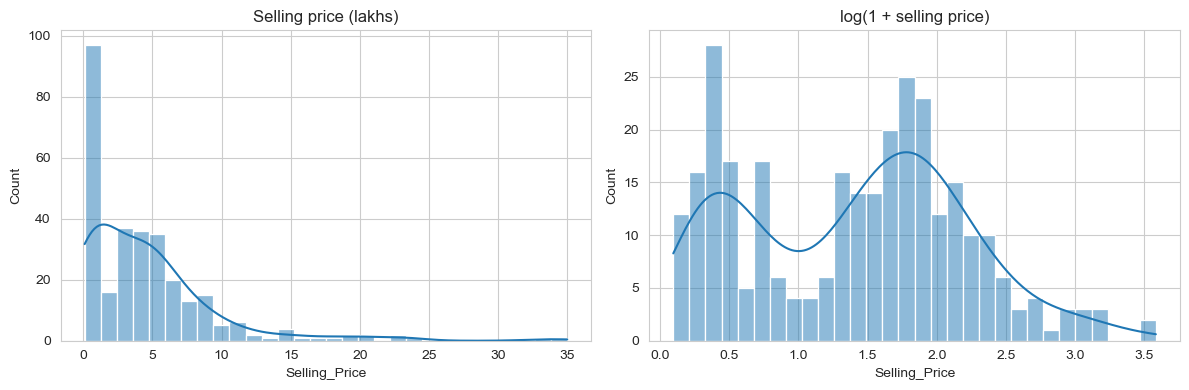

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_model["Selling_Price"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Selling price (lakhs)")
sns.histplot(np.log1p(df_model["Selling_Price"]), bins=30, kde=True, ax=axes[1])
axes[1].set_title("log(1 + selling price)")
plt.tight_layout(); plt.show()

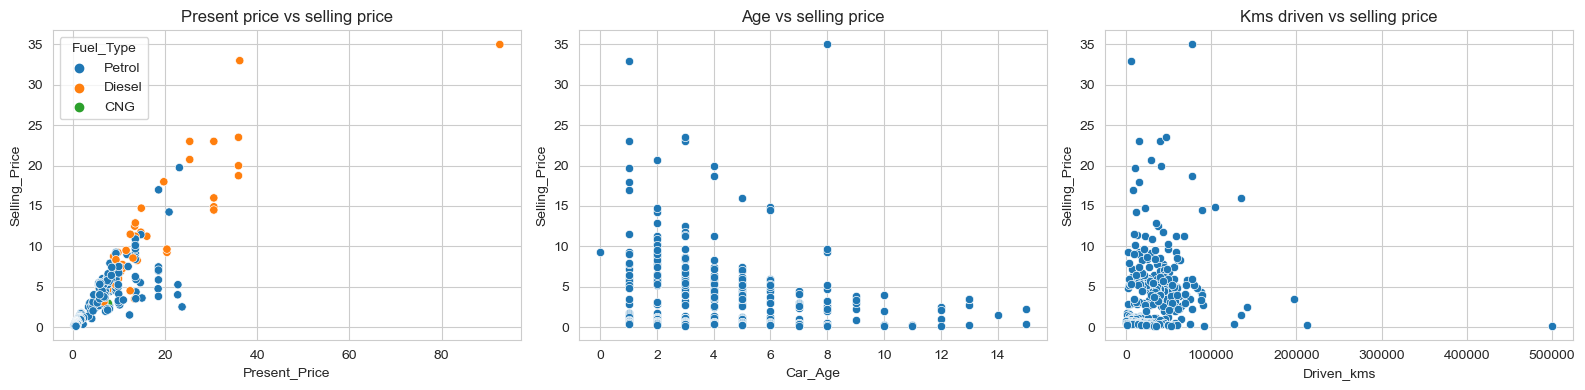

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df_model, x="Present_Price", y="Selling_Price", hue="Fuel_Type", ax=axes[0])
axes[0].set_title("Present price vs selling price")
sns.scatterplot(data=df_model, x="Car_Age", y="Selling_Price", ax=axes[1])
axes[1].set_title("Age vs selling price")
sns.scatterplot(data=df_model, x="Driven_kms", y="Selling_Price", ax=axes[2])
axes[2].set_title("Kms driven vs selling price")
plt.tight_layout(); plt.show()

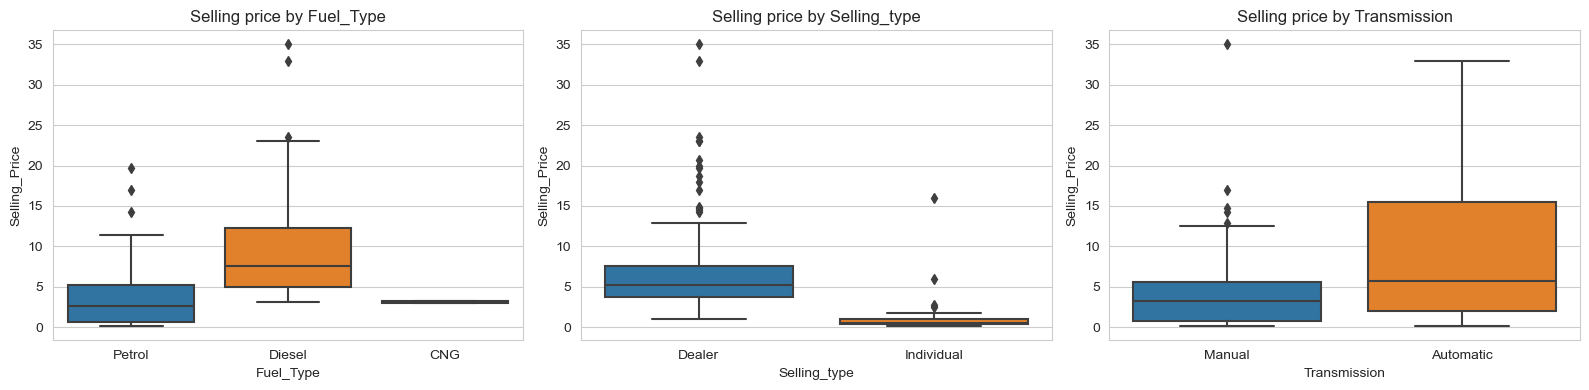

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Fuel_Type", "Selling_type", "Transmission"]):
    sns.boxplot(data=df_model, x=col, y="Selling_Price", ax=ax)
    ax.set_title(f"Selling price by {col}")
plt.tight_layout(); plt.show()

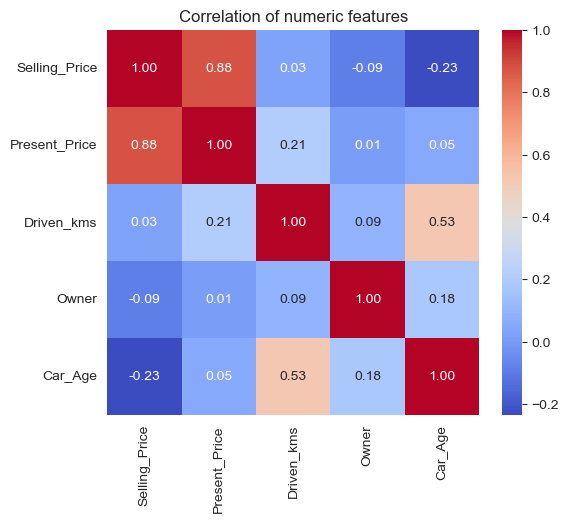

In [10]:
plt.figure(figsize=(6, 5))
sns.heatmap(df_model.select_dtypes("number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation of numeric features")
plt.show()

**What the plots show**
- Selling price is right-skewed: most vehicles are cheap and a few cars are very expensive. Using a log transform on the target helps the models.
- Present price is by far the strongest predictor of selling price.
- Older vehicles and those with many kilometres tend to sell for less, and dealer-sold vehicles tend to be priced higher than individual-sold ones.
- This dataset also contains motorcycles and scooters (the low-price rows), not only cars.

## 5. Train / test split
80% of the data trains the model and 20% is kept hidden for the final test.

In [11]:
X = df_model.drop(columns="Selling_Price")
y = df_model["Selling_Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (239, 7)  Test: (60, 7)


## 6. Preprocessing pipeline
- `Present_Price` and `Driven_kms` have extreme outliers (a Land Cruiser at 92.6 lakhs, a scooter with 500,000 km), so they are log-transformed and then scaled.
- Other numeric columns are scaled.
- Categorical columns (fuel type, seller type, transmission) are one-hot encoded.
- The target is log-transformed during training and converted back for predictions, so errors stay in lakhs.

Everything sits in one pipeline, so all transformations are learned from the training data only (no data leakage).

*Note: I first tried the raw (untransformed) features. Linear models then gave wildly unstable cross-validation scores because of the outliers, which is why the log transform is used.*

In [12]:
log_cols = ["Present_Price", "Driven_kms"]
num_cols = ["Car_Age", "Owner"]
cat_cols = ["Fuel_Type", "Selling_type", "Transmission"]

preprocess = ColumnTransformer([
    ("log", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), log_cols),
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

def build(model):
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

## 7. Compare models
Four regression models are compared with 5-fold cross-validation on the training set (R² score; higher is better).

Linear Regression    CV R2: 0.955 (+/- 0.016)
Ridge Regression     CV R2: 0.953 (+/- 0.016)
Random Forest        CV R2: 0.895 (+/- 0.095)
Gradient Boosting    CV R2: 0.897 (+/- 0.128)


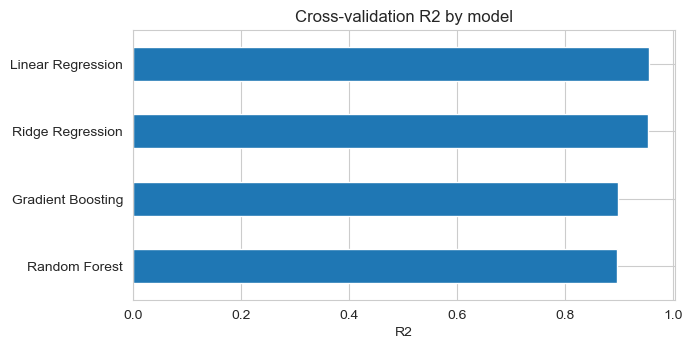

In [13]:
models = {
    "Linear Regression": build(LinearRegression()),
    "Ridge Regression": build(Ridge(alpha=1.0)),
    "Random Forest": build(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)),
    "Gradient Boosting": build(GradientBoostingRegressor(random_state=RANDOM_STATE)),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2")
    cv_results[name] = scores
    print(f"{name:20s} CV R2: {scores.mean():.3f} (+/- {scores.std():.3f})")

pd.Series({k: v.mean() for k, v in cv_results.items()}).sort_values().plot(
    kind="barh", figsize=(7, 3.5), title="Cross-validation R2 by model")
plt.xlabel("R2"); plt.show()

## 8. Evaluate every model on the test set

In [14]:
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "R2": r2_score(y_test, pred),
        "MAE (lakhs)": mean_absolute_error(y_test, pred),
        "RMSE (lakhs)": np.sqrt(mean_squared_error(y_test, pred)),
    })
results = pd.DataFrame(rows).set_index("Model").round(3).sort_values("R2", ascending=False)
results

,R2,MAE (lakhs),RMSE (lakhs)
Model,,,
Ridge Regression,0.891,0.957,1.680
Linear Regression,0.890,0.965,1.685
Gradient Boosting,0.844,0.938,2.005
Random Forest,0.656,1.315,2.979


## 9. Final model: actual vs predicted

Best model by cross-validation: Linear Regression


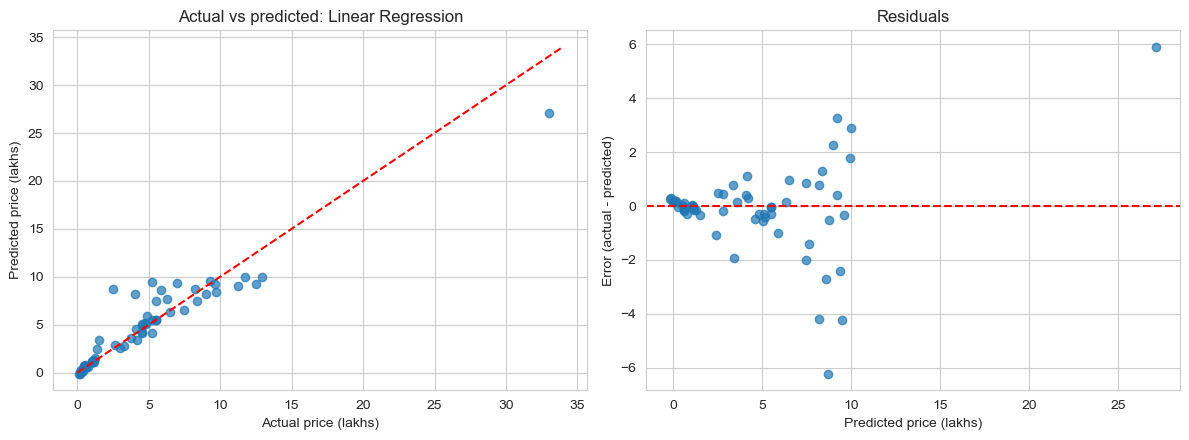

In [15]:
best_name = max(cv_results, key=lambda k: cv_results[k].mean())
print("Best model by cross-validation:", best_name)
best = models[best_name]
pred = best.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, pred, alpha=0.7)
lims = [0, max(y_test.max(), pred.max()) + 1]
axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("Actual price (lakhs)"); axes[0].set_ylabel("Predicted price (lakhs)")
axes[0].set_title(f"Actual vs predicted: {best_name}")

axes[1].scatter(pred, y_test - pred, alpha=0.7)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted price (lakhs)"); axes[1].set_ylabel("Error (actual - predicted)")
axes[1].set_title("Residuals")
plt.tight_layout(); plt.show()

## 10. Which features matter most?

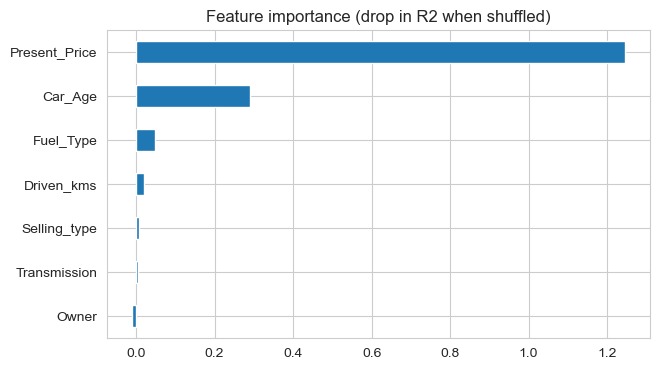

In [16]:
# Permutation importance works for any model: shuffle one feature and see how much the score drops
from sklearn.inspection import permutation_importance
imp = permutation_importance(best, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring="r2")
imp_df = pd.Series(imp.importances_mean, index=X.columns).sort_values()
imp_df.plot(kind="barh", figsize=(7, 4), title="Feature importance (drop in R2 when shuffled)")
plt.show()

## 11. Predict a new car

In [17]:
new_car = pd.DataFrame([{
    "Present_Price": 9.5, "Driven_kms": 30000, "Fuel_Type": "Petrol",
    "Selling_type": "Dealer", "Transmission": "Manual", "Owner": 0, "Car_Age": 4,
}])[X.columns]
print(f"Predicted selling price: {best.predict(new_car)[0]:.2f} lakhs")

Predicted selling price: 5.68 lakhs


## 12. Conclusion
- The best model by cross-validation is Linear Regression (R2 about 0.95), and it scored about 0.89 on the held-out test set with an average error of roughly 1 lakh.
- Present price is by far the most important feature, followed by the age of the vehicle. Fuel type, kilometres driven, seller type, transmission and owner count matter very little.
- Tree-based models (Random Forest, Gradient Boosting) did worse and were less stable here. With only ~300 rows and a few very expensive cars, they cannot predict beyond the prices they have seen, while the linear model on log-transformed features handles the wide price range better.
- Log-transforming the target and the two skewed features, inside a pipeline, was the key step: without it the linear models were very unstable.
- Largest errors are on older, expensive cars (for example an old Camry and Corolla Altis, which sold for far less than the model expected). The model does not know the brand or model, which affects how fast a car loses value.
- Limitations: the dataset is small (about 300 rows), it mixes cars with motorcycles and scooters, and the car name was not used. Adding brand information and more data would likely improve accuracy.